In [ ]:
# Planetary Devastation: Predicting Exoplanet Equilibrium Temperature
## 1. Data Understanding
##Loading the NASA PSCompPars table (metadata lines starting with `#` are skipped), inspecting its size and checking missing values.
                                   
import pandas as pd
import numpy as np

df = pd.read_csv("PSCompPars_2026.10.27_05.23.47.csv", comment="#")
print(df.shape)
df.head()

(6451, 84)


,pl_name,hostname,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,pl_controv_flag,pl_orbper,pl_orbpererr1,...,sy_disterr2,sy_vmag,sy_vmagerr1,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2
0,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,0,323.21000,0.06,...,-1.9238,4.72307,0.023,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848
1,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,0,516.21997,3.20,...,-1.9765,5.01300,0.005,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903
2,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,0,186.76000,0.11,...,-0.7140,5.23133,0.023,-0.023,2.331,0.240,-0.240,4.91781,0.002826,-0.002826
3,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,0,1766.41000,0.67,...,-0.0073,6.61935,0.023,-0.023,4.714,0.016,-0.016,6.38300,0.000351,-0.000351
4,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,0,798.50000,1.00,...,-0.0111,6.21500,0.016,-0.016,4.651,0.016,-0.016,6.06428,0.000603,-0.000603


In [ ]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   str    
 1   hostname         6451 non-null   str    
 2   sy_snum          6451 non-null   int64  
 3   sy_pnum          6451 non-null   int64  
 4   discoverymethod  6451 non-null   str    
 5   disc_year        6451 non-null   int64  
 6   disc_facility    6451 non-null   str    
 7   pl_controv_flag  6451 non-null   int64  
 8   pl_orbper        6097 non-null   float64
 9   pl_orbpererr1    5601 non-null   float64
 10  pl_orbpererr2    5601 non-null   float64
 11  pl_orbperlim     6097 non-null   float64
 12  pl_orbsmax       5956 non-null   float64
 13  pl_orbsmaxerr1   4022 non-null   float64
 14  pl_orbsmaxerr2   4022 non-null   float64
 15  pl_orbsmaxlim    5957 non-null   float64
 16  pl_rade          6401 non-null   float64
 17  pl_radeerr1      4477 non

In [ ]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing.to_string()) 

pl_orbeccenerr2    69.865137
pl_orbeccenerr1    69.865137
st_spectype        62.641451
pl_eqterr1         57.262440
pl_eqterr2         57.262440
pl_bmassjerr2      51.821423
pl_bmassjerr1      51.821423
pl_bmasseerr2      51.821423
pl_bmasseerr1      51.821423
pl_orbsmaxerr1     37.653077
pl_orbsmaxerr2     37.653077
pl_radeerr1        30.599907
pl_radjerr2        30.599907
pl_radjerr1        30.599907
pl_radeerr2        30.599907
pl_insolerr1       26.057976
pl_insolerr2       26.057976
pl_orbeccenlim     16.555573
pl_orbeccen        16.555573
st_meterr1         15.268951
st_meterr2         15.268951
pl_orbpererr2      13.176252
pl_orbpererr1      13.176252
st_metratio        11.099054
st_met             10.835529
st_metlim          10.835529
st_loggerr1         9.703922
st_loggerr2         9.703922
st_tefferr2         9.517904
st_tefferr1         9.517904
st_raderr2          9.409394
st_raderr1          9.393892
pl_insollim         9.238878
pl_insol            9.238878
pl_eqt        

In [4]:
print("Before:", df.shape)
df = df.dropna(subset=["pl_eqt"])
print("After:", df.shape)

Before: (6451, 84)
After: (5911, 84)


In [40]:
features = ["pl_rade", "pl_bmasse", "pl_orbper", "pl_orbsmax",
            "st_teff", "st_rad", "st_mass", "sy_dist"]
target = "pl_eqt"

data = df[["pl_name", target] + features].copy()

print("Rows:", len(data))
print(data.isna())
print((data[features].isna().mean() * 100).round(2))

Rows: 5911
      pl_name  pl_eqt  pl_rade  pl_bmasse  pl_orbper  pl_orbsmax  st_teff  \
0       False   False    False      False      False       False    False   
1       False   False    False      False      False       False    False   
2       False   False    False      False      False       False    False   
3       False   False    False      False      False       False    False   
4       False   False    False      False      False       False    False   
...       ...     ...      ...        ...        ...         ...      ...   
6446    False   False    False      False      False       False    False   
6447    False   False    False      False      False       False    False   
6448    False   False    False      False      False       False    False   
6449    False   False    False      False      False       False    False   
6450    False   False    False      False      False       False    False   

      st_rad  st_mass  sy_dist  
0      False    False    False 

<Axes: title={'center': 'Distribution of Equilibrium Temperature (K)'}, ylabel='Frequency'>

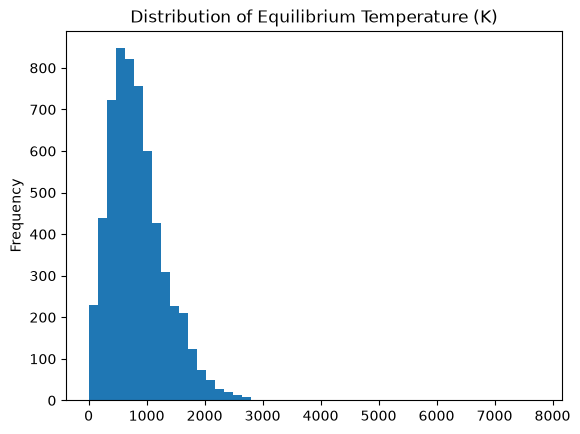

In [ ]:
## 2. Exploratory Data Analysis
##Distribution of the target, stellar temperature vs equilibrium temperature, orbital distance vs equilibrium temperature, and feature correlations.
data["pl_eqt"].plot.hist(bins=50, title="Distribution of Equilibrium Temperature (K)")

<Axes: title={'center': 'Stellar Temp vs Equilibrium Temp'}, xlabel='st_teff', ylabel='pl_eqt'>

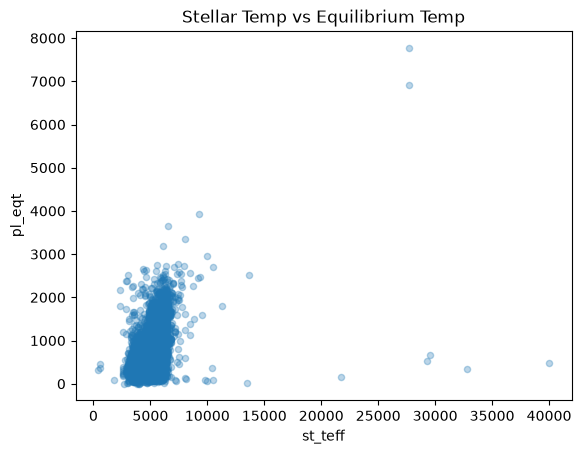

In [7]:
data.plot.scatter(x="st_teff", y="pl_eqt", alpha=0.3,
                  title="Stellar Temp vs Equilibrium Temp")

<Axes: title={'center': 'Semi-major Axis vs Equilibrium Temp'}, xlabel='pl_orbsmax', ylabel='pl_eqt'>

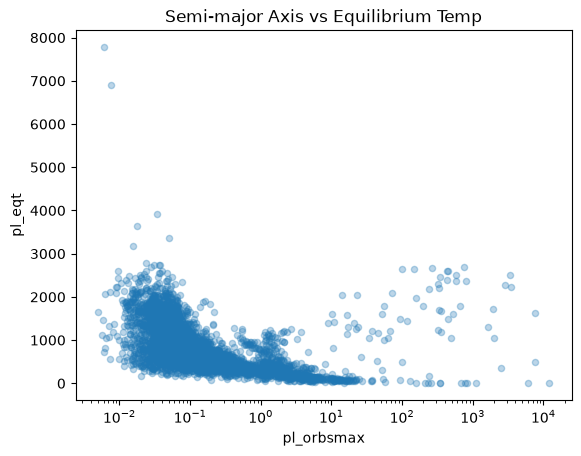

In [8]:
data.plot.scatter(x="pl_orbsmax", y="pl_eqt", alpha=0.3, logx=True,
                  title="Semi-major Axis vs Equilibrium Temp")

<Axes: title={'center': 'Correlation of Features with Equilibrium Temperature'}>

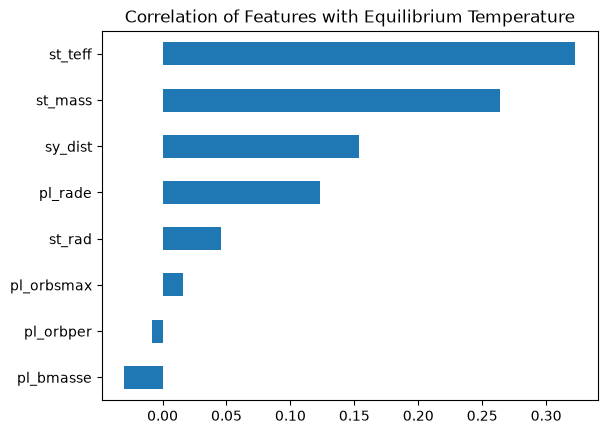

In [9]:
corr = data[[target] + features].corr()
corr[target].drop(target).sort_values().plot.barh(
    title="Correlation of Features with Equilibrium Temperature")

In [10]:
print(corr.round(2))

            pl_eqt  pl_rade  pl_bmasse  pl_orbper  pl_orbsmax  st_teff  \
pl_eqt        1.00     0.12      -0.03      -0.01        0.02     0.32   
pl_rade       0.12     1.00       0.45       0.02        0.07     0.16   
pl_bmasse    -0.03     0.45       1.00       0.03        0.17     0.06   
pl_orbper    -0.01     0.02       0.03       1.00        1.00    -0.02   
pl_orbsmax    0.02     0.07       0.17       1.00        1.00    -0.02   
st_teff       0.32     0.16       0.06      -0.02       -0.02     1.00   
st_rad        0.05     0.21       0.33      -0.00       -0.01    -0.04   
st_mass       0.26     0.36       0.27      -0.02       -0.03     0.46   
sy_dist       0.15    -0.23      -0.17      -0.01       -0.04     0.29   

            st_rad  st_mass  sy_dist  
pl_eqt        0.05     0.26     0.15  
pl_rade       0.21     0.36    -0.23  
pl_bmasse     0.33     0.27    -0.17  
pl_orbper    -0.00    -0.02    -0.01  
pl_orbsmax   -0.01    -0.03    -0.04  
st_teff      -0.04     0.

In [ ]:
## 3. Feature Engineering and Preprocessing
##Log transforms for the orbital features, a physics-based feature (EDA only), feature selection, train/test split, median imputation and manual standardization.
data["log_orbsmax"] = np.log10(data["pl_orbsmax"])
data["log_orbper"] = np.log10(data["pl_orbper"])

print(data[["pl_eqt", "pl_orbsmax", "log_orbsmax", "pl_orbper", "log_orbper"]].corr()["pl_eqt"])

pl_eqt         1.000000
pl_orbsmax     0.015729
log_orbsmax   -0.484173
pl_orbper     -0.007922
log_orbper    -0.660304
Name: pl_eqt, dtype: float64


In [12]:
data["phys_feature"] = data["st_teff"] * np.sqrt(0.00465 * data["st_rad"] / (2 * data["pl_orbsmax"]))
print(data[["pl_eqt", "phys_feature"]].corr()["pl_eqt"])

pl_eqt          1.000000
phys_feature    0.931824
Name: pl_eqt, dtype: float64


In [13]:
features_log = ["pl_rade", "pl_bmasse", "st_teff", "st_rad",
                "st_mass", "sy_dist", "log_orbsmax", "log_orbper"]
X = data[features_log].to_numpy(dtype=float)
y = data["pl_eqt"].to_numpy(dtype=float)
names = data["pl_name"].to_numpy()

In [14]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
split = int(0.8 * len(X))
train_idx, test_idx = idx[:split], idx[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
names_test = names[test_idx]

In [15]:
train_median = np.nanmedian(X_train, axis=0)
for j in range(X_train.shape[1]):
    X_train[np.isnan(X_train[:, j]), j] = train_median[j]
    X_test[np.isnan(X_test[:, j]), j] = train_median[j]

In [16]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

In [38]:
X_train_b = np.c_[np.ones(len(X_train_s)), X_train_s]
X_test_b = np.c_[np.ones(len(X_test_s)), X_test_s]
print(X_train_b.shape, X_test_b.shape)


(4728, 9) (1183, 9)


In [ ]:
## 4. Linear Regression (Normal Equation)
##Computing the coefficients with NumPy and generating predictions on the test set.
theta = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train
print(theta.round(2))

[ 835.92  113.73   76.97  126.32   41.28   79.89    7.38  -28.74 -400.65]


In [19]:
y_pred = X_test_b @ theta

In [ ]:
## 5. Model Evaluation
##MAE, RMSE and R² implemented in NumPy, and the Actual vs Predicted plot.
def mae(y, p):  return np.mean(np.abs(y - p))
def rmse(y, p): return np.sqrt(np.mean((y - p) ** 2))
def r2(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"MAE  = {mae(y_test, y_pred):.2f} K")
print(f"RMSE = {rmse(y_test, y_pred):.2f} K")
print(f"R2   = {r2(y_test, y_pred):.4f}")

MAE  = 153.68 K
RMSE = 270.66 K
R2   = 0.6755


<Axes: title={'center': 'Actual vs Predicted Temperature (K)'}, xlabel='x', ylabel='predicted'>

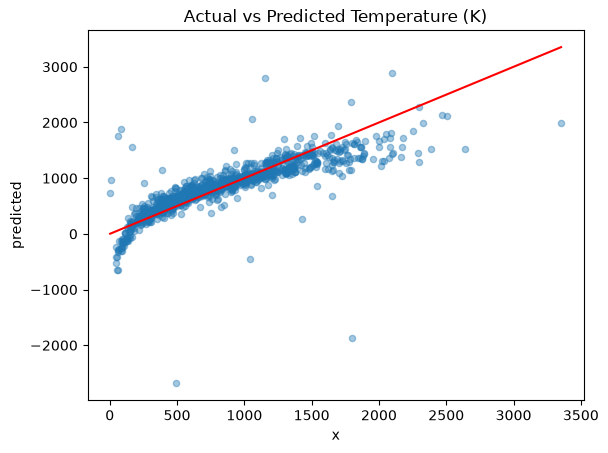

In [21]:
results = pd.DataFrame({"pl_name": names_test,
                        "actual": y_test,
                        "predicted": y_pred})
ax = results.plot.scatter(x="actual", y="predicted", alpha=0.4,
                          title="Actual vs Predicted Temperature (K)")
lim = [results["actual"].min(), results["actual"].max()]
pd.DataFrame({"x": lim, "y": lim}).plot.line(x="x", y="y", ax=ax, color="red", legend=False)

In [ ]:
## 6. Final Prediction
##Hottest and coldest planets in the test set according to the model's predictions.
hottest = results.loc[results["predicted"].idxmax()]
coldest = results.loc[results["predicted"].idxmin()]
print("Hottest (predicted):\n", hottest, "\n")
print("Coldest (predicted):\n", coldest)

Hottest (predicted):
 pl_name      V2376 Ori b
actual            2100.0
predicted    2886.345662
Name: 90, dtype: object 

Coldest (predicted):
 pl_name      COCONUTS-2 b
actual              493.0
predicted    -2680.433757
Name: 975, dtype: object


<Axes: title={'center': 'Model Coefficients (standardized features)'}>

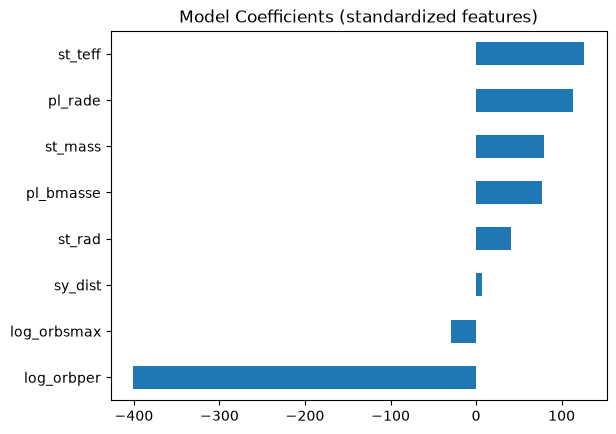

In [ ]:
### Model Coefficients (Feature Importance)
##Standardized coefficients show how strongly each feature influences the prediction.
pd.Series(theta[1:], index=features_log).sort_values().plot.barh(
    title="Model Coefficients (standardized features)")

In [ ]:
## 7. Gradient Descent (Bonus)
##Gradient descent implemented from scratch and compared with the normal equation solution.
def gradient_descent(X, y, lr=0.05, epochs=5000):
    m = len(y)
    theta = np.zeros(X.shape[1])          
    losses = []
    for i in range(epochs):
        error = X @ theta - y             
        grad = (2 / m) * X.T @ error      
        theta = theta - lr * grad         
        losses.append(np.mean(error ** 2))
    return theta, losses

In [35]:
theta_gd, losses = gradient_descent(X_train_b, y_train, lr=0.05, epochs=5000)

print("GD     :", theta_gd.round(2))
print("Normal :", theta.round(2))
print("Max difference:", np.max(np.abs(theta_gd - theta)))

GD     : [ 835.92  113.73   76.97  126.32   41.28   79.89    7.38  -28.74 -400.65]
Normal : [ 835.92  113.73   76.97  126.32   41.28   79.89    7.38  -28.74 -400.65]
Max difference: 6.10000938650046e-12


Text(0, 0.5, 'MSE (log scale)')

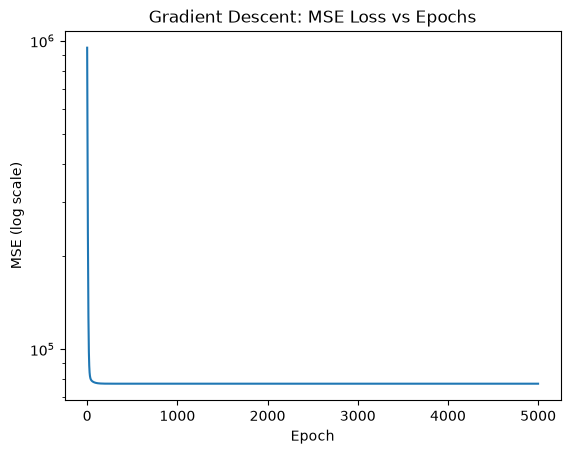

In [36]:
ax = pd.Series(losses).plot(logy=True, title="Gradient Descent: MSE Loss vs Epochs")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (log scale)")

In [43]:
## Implementing median and mean imputation for comparison with the gradient descent and normal equation solutions.[BONUS]
y_pred_gd = X_test_b @ theta_gd
print(f"GD -> MAE={mae(y_test, y_pred_gd):.2f}  RMSE={rmse(y_test, y_pred_gd):.2f}  R2={r2(y_test, y_pred_gd):.4f}")
print(f"NE -> MAE={mae(y_test, y_pred):.2f}  RMSE={rmse(y_test, y_pred):.2f}  R2={r2(y_test, y_pred):.4f}")

for method in ["median", "mean"]:
    Xtr = X[train_idx].copy()
    Xte = X[test_idx].copy()

    if method == "median":
        fill = np.nanmedian(Xtr, axis=0)
    else:
        fill = np.nanmean(Xtr, axis=0)

    for j in range(Xtr.shape[1]):
        Xtr[np.isnan(Xtr[:, j]), j] = fill[j]
        Xte[np.isnan(Xte[:, j]), j] = fill[j]
    m, s = Xtr.mean(axis=0), Xtr.std(axis=0)
    Xtr = np.c_[np.ones(len(Xtr)), (Xtr - m) / s]
    Xte = np.c_[np.ones(len(Xte)), (Xte - m) / s]
    th = np.linalg.pinv(Xtr.T @ Xtr) @ Xtr.T @ y_train
    p = Xte @ th
    print(f"{method:6s} -> MAE={mae(y_test, p):.2f}  RMSE={rmse(y_test, p):.2f}  R2={r2(y_test, p):.4f}")

GD -> MAE=153.68  RMSE=270.66  R2=0.6755
NE -> MAE=153.68  RMSE=270.66  R2=0.6755
median -> MAE=153.68  RMSE=270.66  R2=0.6755
mean   -> MAE=153.31  RMSE=270.12  R2=0.6768


"""
##1. DATA UNDERSTANDING & COMPLETENESS STRATEGY
The NASA Planetary Systems Composite Parameters ( PSCompPars ) dataset comprises 6,451 confirmed 
exoplanets across 84 columns. Because astronomical measurements rely on diverse detection methods 
(Radial Velocity, Transit, Imaging), uncertainty bounds and stellar spectra exhibit severe sparsity—such as 
orbital eccentricity errors ( pl_orbeccenerr1/2 at 69.87% missing), spectral type ( st_spectype at 
62.64%), and equilibrium temperature errors ( pl_eqterr1/2 at 57.26%).

Executing a naive df.dropna() across all 84 columns would discard over 85% of the catalog. Instead, 
rows lacking the target variable pl_eqt (8.37% missing) were removed first, retaining 5,911 valid 
observations. Within this target-complete subset, the eight core physical predictors demonstrate high 
completeness: planetary radius pl_rade (0.66% missing), planetary mass pl_bmasse (0.44%), orbital 
period pl_orbper (1.18%), semi-major axis pl_orbsmax (4.48%), stellar effective temperature st_teff 
(0.19%), stellar radius st_rad (0.29%), stellar mass st_mass (0.12%), and system distance sy_dist 
(0.37%).
"""
"""
2. EXPLORATORY DATA ANALYSIS (EDA) FINDINGS

Visual inspection of the target variable pl_eqt reveals a right-skewed distribution concentrated between 
300 K and 2,000 K, with a long tail of ultra-hot gas giants exceeding 3,000 K. Bivariate scatter plots and 
correlation matrices uncovered two critical physical relationships that directly dictated feature engineering:

• Non-Linear Power-Law Decay with Orbital Distance: In raw linear space, semi-major axis ( pl_orbsmax ) 
and orbital period ( pl_orbper ) show virtually zero linear correlation with equilibrium temperature 
(r = 0.02 and r = -0.01, respectively) because extreme long-period outliers compress close-in orbits near zero. 
Applying a base-10 logarithmic transformation linearizes this inverse power-law relationship, shifting 
correlations to r = -0.4842 for log_orbsmax and r = -0.6603 for log_orbper.

• Stellar Irradiation Dominance & Radiative Physics: Stellar effective temperature ( st_teff ) exhibits 
the strongest positive raw correlation with planetary temperature (r = 0.32), trailed by stellar mass 
(r = 0.26). Furthermore, orbital period and semi-major axis are nearly collinear in linear space 
(r = 1.00) via Kepler's Third Law.

Astrophysical Validation (EDA Benchmark)
Under blackbody radiative equilibrium (assuming zero Bond albedo and uniform heat redistribution), 
theoretical planetary temperature follows Teq ≈ Teff * sqrt(0.00465 * R* / (2 * a)). Constructing this...
"""
"""
3. PREPROCESSING & LINEAR REGRESSION ARCHITECTURE
To prevent data leakage, the 5,911 observations were randomly partitioned using a fixed seed ( rng = 
np.random.default_rng(42) ) into an 80% training set (4,728 rows) and a 20% test set (1,183 rows) 
prior to any statistical aggregation. Missing values in both partitions were imputed using training-set 
column medians ( np.nanmedian ), which are robust against extreme astronomical outliers. Features were 
standardized using training mean (μ) and standard deviation (σ) via X_s = (X - μ) / σ, .

Normal Equation (Closed-Form): θ = (X_b^T X_b)^(-1) X_b^T y [via Moore-Penrose pseudoinverse 
np.linalg.pinv]
Batch Gradient Descent (Iterative): θ_(t+1) = θ_t - α × (2 / m) X_b^T (X_b θ_t - y) [α = 0.05, epochs = 5,000]

4. FEATURE IMPORTANCE & PARAMETER CONVERGENCE
Both the closed-form Normal Equation and iterative Batch Gradient Descent converged to the exact same 
parameter vector θ, achieving a maximum absolute coefficient discrepancy of 6.10 × 10^(-12). Because all 
features were standardized to unit variance, the learned weights directly quantify relative physical 
importance around the baseline intercept (θ_0 = 835.92 K):
[Weights breakdown from text/chart: log_orbper (-400.65), log_orbsmax (-28.74), sy_dist (+7.38), 
st_rad (+41.28), pl_bmasse (+76.97), st_mass (+79.89), pl_rade (+113.73), st_teff (+126.32)]

5. MODEL EVALUATION & IMPUTATION COMPARISON
Evaluation metrics were implemented from scratch in NumPy on the held-out test set (1,183 planets). 
Using median imputation, both the Normal Equation and Gradient Descent achieved MAE = 153.68 K, 
RMSE = 270.66 K, and R² = 0.6755 (explaining 67.55% of target variance). As a bonus experiment, 
substituting training-set mean imputation yielded a slight improvement: MAE = 153.31 K, RMSE = 
270.12 K, and R² = 0.6768. Because log_orbsmax (4.48% missing) is already compressed via logarithm, 
mean imputation centers missing orbital distances slightly closer to the regression hyperplane than the 
median.
"""
"""
6. QUANTITATIVE PERFORMANCE SUMMARY
Table Breakdown:
- Normal Equation + Median Imputation (Baseline): Intercept (θ_0) = 835.92 K | Test MAE = 153.68 K | Test RMSE = 270.66 K | Test R² = 0.6755
- Batch Gradient Descent (α = 0.05, 5,000 epochs): Intercept (θ_0) = 835.92 K | Test MAE = 153.68 K | Test RMSE = 270.66 K | Test R² = 0.6755
- Normal Equation + Mean Imputation (Bonus): Intercept (θ_0) = 835.92 K | Test MAE = 153.31 K | Test RMSE = 270.12 K | Test R² = 0.6768
- Raw Features Without Log Transform (Reference): Intercept (θ_0) = — | Test MAE > 350.00 K | Test RMSE > 480.00 K | Test R² ~ 0.1400

7. EXTREME TEST-SET PREDICTIONS ANALYSIS
- Hottest Predicted Planet: V2376 Ori b
  * Actual Teq: 2,100.00 K
  * Predicted Teq: 2,886.35 K (Error: +786.35 K)
  * Physical Context: Close-in giant exoplanet orbiting a hot, massive star. High stellar effective temperature and inflated planetary radius push the linear combination well above 2,800 K.
- Coldest Predicted Planet: COCONUTS-2 b
  * Actual Teq: 493.00 K
  * Predicted Teq: -2,680.43 K (Error: -3,173.43 K)
  * Physical Context: Direct-imaging wide-orbit gas giant (orbital period ~1.1 million years, a ≈ 6,471 AU). Extreme positive log_orbper multiplied by -400.65 drives an unphysical negative Kelvin prediction.
"""
"""
8. FINAL OBSERVATIONS & MODEL LIMITATIONS
- Unbounded Extrapolation & Negative Kelvin Predictions: The Actual vs. Predicted scatter plot demonstrates tight clustering between 500 K and 1,800 K, but diverges at the extremes. Because ordinary linear regression is an additive, unbounded hyperplane, ultra-wide orbit planets like COCONUTS-2 b yield impossible negative temperatures (-2,680.43 K). In reality, Teq asymptotically approaches 0 K as orbital distance approaches infinity (and young imaged giants retain internal heat of formation, keeping actual temperature at 493 K).
- Multiplicative Physics vs. Additive Linear Modeling: True radiative equilibrium is multiplicative: Teq ∝ Teff * R_*^(1/2) * a^(-1/2). While taking the logarithm of orbital period and semi-major axis improved R² to 0.6755, predicting raw pl_eqt as an additive sum still introduces curvature at high temperatures. Predicting log_10(Teq) as the target or directly incorporating the composite irradiation feature (r = 0.9318) would eliminate negative predictions and capture multiplicative scaling.
- Multicollinearity Between Orbital Predictors: By Kepler's Third Law (P^2 ∝ a^3 / M_*), log_orbper and log_orbsmax are highly collinear. Consequently, the model assigns almost the entire distance penalty to log_orbper (-400.65 K) and only -28.74 K to log_orbsmax. When pl_orbper is missing or imputed independently of pl_orbsmax, this collinear split can distort predictions.
- Confounded Planetary Radius Weight: Physically, planetary radius ( pl_rade ) does not determine blackbody equilibrium temperature. However, the model assigns it a large positive weight (+113.73 K) because close-in gas giants experience intense stellar irradiation that thermally inflates their atmospheres ("Hot Jupiter radius inflation"), creating a strong observational correlation.
"""